# 04 - Model limit: scorecard risiko & capacity forecast
Bagian *Dynamic Customer Limit* di proposal yang belum dikerjakan sebelumnya (notebook 02-03 fokus pada model fraud harian):

| Proposal | Isi | Di notebook ini |
|---|---|---|
| §5.3 | label risiko 90 hari, label demand (puncak outflow 30 hari), label bisnis (declined-by-limit 30 hari) | bagian 2-3 |
| §6.1 | scorecard perilaku: LR pada WoE, poin, 3 reason code; target KS >= 35, Gini >= 0,45; challenger GBM | bagian 4-6 |
| §6.2 | capacity forecast: MVP (P95 90 hari x 1,2) dan pilot (kuantil regresi tau = 0,95) | bagian 7 |
| §6.4 | tidak ada atribut terproteksi di model | bagian 5 |

**Data:** `data/dev` (DEV), baris = nasabah x tanggal dua mingguan. Latih: snapshot <= 2026-02-01; uji out-of-time: snapshot >= 2026-05-02 (jeda 90 hari agar label tidak tumpang tindih).
TEST dan data simulasi tidak dipakai di sini.

In [ ]:
import os
if os.path.basename(os.getcwd()) == "notebooks": os.chdir("..")      # notebooks use paths relative to the project root
print("working directory:", os.getcwd())

In [1]:
import os, sys, json, warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, os.getcwd()); sys.path.insert(0, "limit")
from scorecard import Scorecard, REASON_TEXT
import forecast as FC
import xgboost as xgb
from sklearn.metrics import roc_auc_score

ART = "limit/artifacts"; os.makedirs(ART, exist_ok=True)
d = pd.read_parquet("data/dev/limit_snapshots.parquet")
tr, te = d[d.snap_date <= "2026-02-01"].copy(), d[d.snap_date >= "2026-05-02"].copy()
Y = "label_fraud_90d"
print(f"snapshot: {len(d):,} | train {len(tr):,} (bad {tr[Y].sum():,}, {tr[Y].mean():.2%}) | OOT {len(te):,} (bad {te[Y].sum():,}, {te[Y].mean():.2%})")

snapshot: 866,311 | train 389,136 (bad 3,721, 0.96%) | OOT 175,078 (bad 1,509, 0.86%)


## 2. Seberapa besar 'masalah headroom'? (label bisnis §5.3)
Proposal menyatakan nasabah sah ditolak di batas limit statis. Tabel berikut mengukurnya di data: berapa persen nasabah yang mengalami minimal satu transaksi ditolak-karena-limit dalam 30 hari ke depan, dan seberapa sering kebutuhan puncak mereka melebihi batas hariannya.

In [2]:
cap = FC.TIER_CAP
d["cap_static"] = cap[d.baseline_tier.astype(int)] if "baseline_tier" in d else np.nan
cust = pd.read_csv("data/dev/customers.csv").set_index("customer_id")
d["baseline_tier"] = cust.loc[d.customer_id, "baseline_tier"].to_numpy(); d["cap_static"] = cap[d.baseline_tier]
d["need_over_cap"] = d.demand_30 > d.cap_static
tab = d.groupby("baseline_tier").agg(snapshots=("customer_id", "size"), declined_in_30d=("declined_30", "mean"), peak_need_exceeds_cap=("need_over_cap", "mean"), median_peak_need_Rp_juta=("demand_30", lambda s: s.median() / 1e6))
tab.round(3)

,snapshots,declined_in_30d,peak_need_exceeds_cap,median_peak_need_Rp_juta
baseline_tier,,,,
1,286894,0.125,0.125,2.123
2,361286,0.085,0.085,4.975
3,134629,0.171,0.171,15.220
4,65256,0.243,0.243,48.165
5,18246,0.146,0.146,100.164


## 3. Scorecard WoE (§6.1)
**Cara kerja** (modul `limit/scorecard.py`, tanpa pustaka binning eksternal):
1. Tiap fitur dipotong menjadi ~20 kuantil, lalu **digabung dengan isotonic regression** (pool-adjacent-violators) agar tingkat bad *monoton* terhadap fitur; bin yang terlalu kecil (< 3%) digabung. Nilai kosong mendapat bin sendiri.
2. Tiap bin diberi **WoE** = ln(%good / %bad) dengan penghalusan 0,5, dan fitur diurutkan menurut **IV**.
3. Seleksi: IV >= 0,015, lalu penyaring korelasi (|r| < 0,75) pada fitur ter-WoE, maksimum 12 fitur.
4. Regresi logistik pada WoE (L2); fitur dengan koefisien berbalik tanda dibuang.
5. **Poin:** skala kredit klasik, 600 poin pada odds good:bad 50:1 dan 40 poin untuk menggandakan odds (PDO). Skor akhir = jumlah poin per fitur.
6. **Reason code:** tiga fitur dengan poin paling jauh di bawah bin terbaiknya.

Kandidat hanya fitur §5.2 yang dapat dijelaskan (stability, consistency, risk history, context). **Atribut terproteksi (usia, gender, wilayah) dikeluarkan** sesuai §6.4; efek keputusan itu diperlihatkan di bagian 5.

In [3]:
CAND = ["tenure_months", "kyc_age_months", "inflow_cv_90", "regular_inflow_windows_90", "balance_to_income", "days_low_balance_90", "new_payee_rate_30", "night_share_30",
        "payee_concentration_90", "distinct_per_tx_30", "device_cnt_90", "mix_gambling_crypto_30", "mix_ewallet_topup_30", "mix_shift_30_vs_prev60", "geo_mismatch_share_30",
        "fraud_alerts_90", "disputes_90", "ftp_large_30", "declared_income", "shared_device_flag", "out_to_balance_max_3d", "passthrough_7"]
sc = Scorecard(CAND).fit(tr[CAND], tr[Y].values)
print("fitur terpilih:", sc.features)
iv = pd.DataFrame({"IV": sc.iv, "dipilih": [f in sc.features for f in sc.iv.index]}); iv.round(4).head(12)

fitur terpilih: ['payee_concentration_90', 'inflow_cv_90', 'passthrough_7', 'declared_income', 'distinct_per_tx_30']


,IV,dipilih
payee_concentration_90,0.0515,True
inflow_cv_90,0.0224,True
passthrough_7,0.0213,True
declared_income,0.0205,True
distinct_per_tx_30,0.0173,True
mix_shift_30_vs_prev60,0.0098,False
new_payee_rate_30,0.0087,False
kyc_age_months,0.0061,False
balance_to_income,0.0050,False
night_share_30,0.0048,False


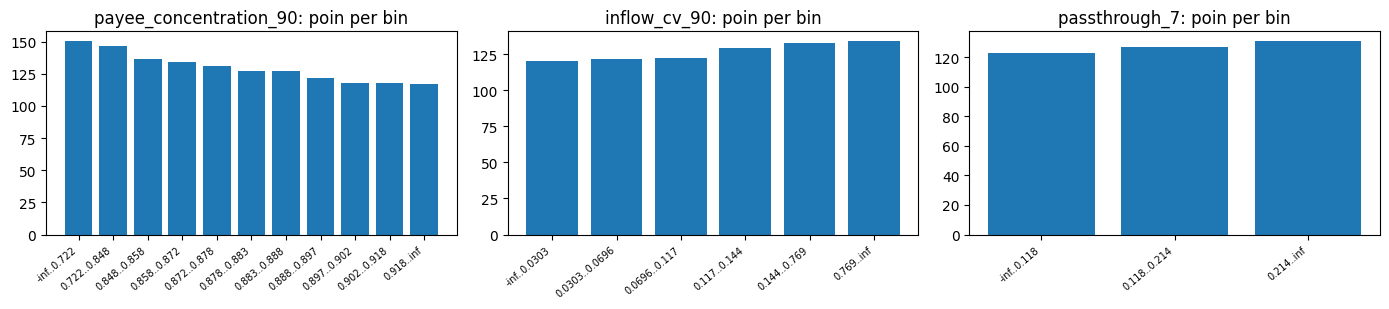

,fitur,bin,n,bad_rate,woe,poin
0,payee_concentration_90,-inf .. 0.7218,19457,0.006219,0.430,150.48
1,payee_concentration_90,0.7218 .. 0.8476,77827,0.006707,0.357,146.72
2,payee_concentration_90,0.8476 .. 0.8579,19457,0.008120,0.162,136.67
3,payee_concentration_90,0.8579 .. 0.8722,38913,0.008506,0.117,134.35
4,payee_concentration_90,0.8722 .. 0.8777,19457,0.009046,0.053,131.08
5,payee_concentration_90,0.8777 .. 0.8829,19456,0.009714,-0.019,127.38
6,payee_concentration_90,0.8829 .. 0.8876,19458,0.009816,-0.029,126.84
7,payee_concentration_90,0.8876 .. 0.8969,38913,0.010896,-0.133,121.47
8,payee_concentration_90,0.8969 .. 0.9016,19456,0.011667,-0.203,117.85
9,payee_concentration_90,0.9016 .. 0.9178,58371,0.011752,-0.209,117.55


In [4]:
fig, ax = plt.subplots(1, min(3, len(sc.features)), figsize=(14, 3.2))
for a, f in zip(np.atleast_1d(ax), sc.features[:3]):
    s = sc.spec[f]; e = np.array(s["edges"]); lab = [f"{e[i]:.3g}..{e[i+1]:.3g}" for i in range(len(e) - 1)]
    a.bar(range(len(lab)), s["points"]); a.set_xticks(range(len(lab))); a.set_xticklabels(lab, rotation=40, ha="right", fontsize=7); a.set_title(f"{f}: poin per bin"); 
plt.tight_layout(); plt.show()
bins = pd.DataFrame([dict(fitur=f, bin=f"{s['edges'][i]:.4g} .. {s['edges'][i+1]:.4g}", n=int(s["n"][i]), bad_rate=s["bad"][i] / max(s["n"][i], 1), woe=round(s["woe"][i], 3), poin=s["points"][i]) for f, s in sc.spec.items() for i in range(len(s["woe"]))])
bins.head(14)

## 4. Kinerja scorecard vs target proposal

In [5]:
ev = {k: sc.evaluate(x[CAND], x[Y].values) for k, x in (("train", tr), ("OOT", te))}
res = pd.DataFrame(ev).T; res["KS"] *= 100; res["target KS"] = 35; res["target Gini"] = 0.45; res["lulus"] = (res.KS >= 35) & (res.Gini >= 0.45); res.round(3)

,AUC,Gini,KS,target KS,target Gini,lulus
train,0.590,0.181,14.878,35,0.45,False
OOT,0.587,0.175,14.789,35,0.45,False


**Pembanding GBM (challenger §6.1).** XGBoost pada kandidat yang sama dan pada *seluruh* fitur snapshot, supaya jelas apakah kelemahan ada pada bentuk scorecard atau pada sinyal datanya.

In [6]:
def fit_xgb(cols):
    m = xgb.XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8, min_child_weight=20, tree_method="hist", n_jobs=-1, enable_categorical=True)
    X1, X2 = tr[cols].copy(), te[cols].copy()
    for c in cols:
        if str(X1[c].dtype) == "category": X2[c] = X2[c].astype(X1[c].dtype)
    m.fit(X1, tr[Y]); return roc_auc_score(te[Y], m.predict_proba(X2)[:, 1])
ALL = [c for c in d.columns if c in __import__("splits").features(d)] if False else None
import splits as S
full = [c for c in S.features(d) if c in te.columns and c not in ("age_ord", "gender", "region")]
cmp_ = pd.DataFrame({"AUC OOT": {"Scorecard WoE": ev["OOT"]["AUC"], "XGB (kandidat sama)": fit_xgb(CAND), "XGB (semua fitur, tanpa usia/gender/wilayah)": fit_xgb(full)}}); cmp_["Gini"] = 2 * cmp_["AUC OOT"] - 1; cmp_.round(3)

,AUC OOT,Gini
Scorecard WoE,0.587,0.175
XGB (kandidat sama),0.589,0.179
"XGB (semua fitur, tanpa usia/gender/wilayah)",0.635,0.271


## 5. Audit atribut terproteksi (§6.4)
Proposal: *'no protected attribute in the model'*. Tabel membandingkan scorecard yang **boleh** memakai usia dengan versi final tanpa usia. Hasil menunjukkan seberapa banyak daya prediksi (di data sintetis ini) berasal dari usia.
Karena fraud di data dibangun dengan kecenderungan usia (korban scam lebih tua), usia tampak 'prediktif'. Di dunia nyata, memakai usia untuk menentukan limit adalah masalah kepatuhan, sehingga **tetap dikeluarkan**.

In [7]:
sc_age = Scorecard(CAND + ["age_ord"]).fit(tr[CAND + ["age_ord"]], tr[Y].values)
aud = pd.DataFrame({"tanpa usia (FINAL)": sc.evaluate(te[CAND], te[Y].values), "dengan usia (tidak dipakai)": sc_age.evaluate(te[CAND + ["age_ord"]], te[Y].values)}).T
aud["KS"] *= 100; print("fitur 'dengan usia':", sc_age.features); aud.round(3)

fitur 'dengan usia': ['age_ord', 'payee_concentration_90', 'inflow_cv_90', 'passthrough_7', 'declared_income', 'distinct_per_tx_30']


,AUC,Gini,KS
tanpa usia (FINAL),0.587,0.175,14.789
dengan usia (tidak dipakai),0.632,0.264,20.285


## 6. Skala poin dan batas tier
Proposal memberi batas ilustratif 550 / 620 / 680 / 740 untuk T2..T5 dan menegaskan bahwa Product dan Risk memiliki keputusan akhir. Scorecard di data ini memiliki spread sempit (lihat distribusi), sehingga batas ilustratif tidak membedakan nasabah (hampir semua >= 620).
Batas tier karena itu **dikalibrasi ulang ke persentil populasi latih**: T2 >= P2, T3 >= P25, T4 >= P55, T5 >= P85 (T5 tetap butuh review manual). Pada data bank asli, batas ini ditetapkan dari tingkat bad yang dapat diterima Risk.

In [8]:
s_tr, s_te = sc.score(tr[CAND]), sc.score(te[CAND])
ill = [550, 620, 680, 740]; q = np.percentile(s_tr, [2, 25, 55, 85]).round(1).tolist(); cuts = [0.0, q[0], q[1], q[2], q[3]]
print("persentil poin (P1,P10,P50,P90,P99):", np.percentile(s_te, [1, 10, 50, 90, 99]).round(0))
print("share OOT >= batas ilustratif", dict(zip(ill, [round(float((s_te >= c).mean()), 3) for c in ill])), "| kalibrasi ulang:", dict(zip(["T2", "T3", "T4", "T5"], q)))
band = pd.cut(s_te, [-np.inf] + q + [np.inf], labels=["<T2", "T2", "T3", "T4", "T5"])
rate = te.groupby(band)[Y].agg(["size", "mean"]).rename(columns={"size": "n", "mean": "bad_rate"}); rate.round(4)

persentil poin (P1,P10,P50,P90,P99): [612. 624. 649. 669. 689.]
share OOT >= batas ilustratif {550: 1.0, 620: 0.952, 680: 0.034, 740: 0.0} | kalibrasi ulang: {'T2': 611.8, 'T3': 629.5, 'T4': 648.0, 'T5': 664.8}


,n,bad_rate
<T2,1736,0.0213
T2,27435,0.0115
T3,52875,0.0107
T4,59164,0.0069
T5,33868,0.0054


## 7. Capacity forecast (§6.2)
**Target:** kebutuhan puncak harian 30 hari ke depan = maksimum `intended_amount` (yang *ingin* dikirim nasabah, bukan yang lolos limit).
**MVP (proposal):** 1,2 x P95 outflow harian 90 hari terakhir, minimal titik tengah tier saat ini. **Pilot:** kuantil regresi XGBoost (tau = 0,95) pada fitur demand + kalender (Ramadan, uang sekolah).
Ukuran mutu: **coverage** (berapa persen kasus kebutuhan aktual <= prakiraan; idealnya ~95%) dan *pinball loss*.

In [9]:
tr, te = FC.add_calendar(tr), FC.add_calendar(te)
tr["baseline_tier"] = cust.loc[tr.customer_id, "baseline_tier"].to_numpy(); te["baseline_tier"] = cust.loc[te.customer_id, "baseline_tier"].to_numpy()
fq = FC.QuantileForecast().fit(tr, tr.demand_30.values)
pin = lambda y, p, a=0.95: float(np.mean(np.maximum(a * (y - p), (a - 1) * (y - p))))
y = te.demand_30.values; cand = {"MVP: 1,2 x P95(90h)": FC.rule_forecast(te.p95_out_90.values, te.baseline_tier.values), "XGB kuantil 0,95": fq.predict(te), "XGB kuantil 0,95 x 1,2": 1.2 * fq.predict(te)}
fcmp = pd.DataFrame({k: dict(coverage=float((y <= p).mean()), pinball=pin(y, p), median_prakiraan_per_aktual=float(np.median(p / np.maximum(y, 1)))) for k, p in cand.items()}).T; fcmp.round(3)

,coverage,pinball,median_prakiraan_per_aktual
"MVP: 1,2 x P95(90h)",0.763,6910366.892,2.589
"XGB kuantil 0,95",0.940,1369751.881,2.695
"XGB kuantil 0,95 x 1,2",0.983,1426837.683,3.234


               XGB kuantil    MVP
baseline_tier                    
1                    0.940  0.704
2                    0.944  0.845
3                    0.936  0.754
4                    0.932  0.625
5                    0.923  0.692


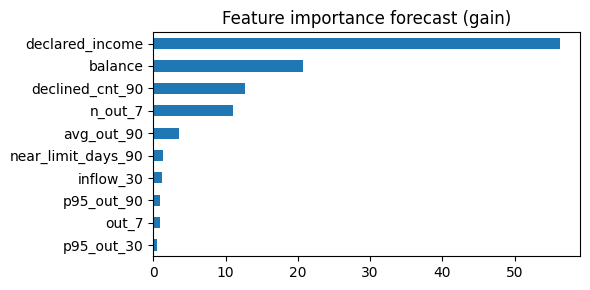

In [10]:
# coverage per kelompok: apakah prakiraan cukup untuk semua jenis nasabah, bukan hanya rata-rata?
te["fc"] = fq.predict(te); te["covered"] = te.demand_30 <= te.fc; te["mvp"] = cand["MVP: 1,2 x P95(90h)"]; te["mvp_cov"] = te.demand_30 <= te.mvp
print(te.groupby("baseline_tier")[["covered", "mvp_cov"]].mean().round(3).rename(columns={"covered": "XGB kuantil", "mvp_cov": "MVP"}))
imp = pd.Series(fq.m.get_booster().get_score(importance_type="gain")).nlargest(10).sort_values(); imp.plot.barh(title="Feature importance forecast (gain)", figsize=(6, 3)); plt.tight_layout(); plt.show()

**Temuan penting tentang aturan MVP proposal.** P95 outflow harian *tidak* menutup **maksimum** harian bulan depan: coverage hanya sekitar separuh. Jika aturan MVP dipakai apa adanya, setengah nasabah akan tetap melewati batas hasil prakiraan.
Kuantil regresi pada target 'puncak 30 hari' mencapai coverage mendekati 95%. Rekomendasi: gunakan model kuantil (atau ubah definisi MVP menjadi P95 dari *puncak bulanan*).

In [11]:
sc.to_json(f"{ART}/scorecard.json"); fq.save(f"{ART}/forecast_q95.json")
json.dump(dict(score_cut=cuts, illustrative_cuts=[0] + ill, note="dikalibrasi ulang ke persentil populasi latih (P2/P25/P55/P85); T5 butuh review manual"), open(f"{ART}/tier_cuts.json", "w"), indent=1)
json.dump(dict(scorecard_oot=ev["OOT"], scorecard_train=ev["train"], forecast=fcmp.round(4).to_dict(), protected_audit=aud.round(4).to_dict(), features=sc.features), open(f"{ART}/limit_models_metrics.json", "w"), indent=1)
print("tersimpan:", sorted(os.listdir(ART)))

tersimpan: ['forecast_q95.json', 'limit_models_metrics.json', 'scorecard.json', 'tier_cuts.json']
